# 04 · Query-based detector: RT-DETR

**Accelerator: GPU T4 x2** Inputs: competition data, `vd-utils`, output of notebook `00`, output of notebook `03` (YOLO metrics and learning curve for the comparison).
The three runs were trained in the previous version of this notebook (training time is logged in `train_h`); this version re-evaluates them from that output (`RUNS_TO_TRAIN = []`) and adds the YOLO curve.

**Protocol:** same split, frames and evaluator as all other detectors (train folds ≠ 0, every 10th masked frame; validate on fold 0 original frames).
**Budget:** each run gets the same wall-clock training time as `v8s_1024` in notebook 03 (**0.41 h on 2×T4**, including per-epoch validation), using Ultralytics' `time` argument;
the number of epochs follows from the budget and the learning-rate schedule is fitted to it.

**Model.** Ultralytics RT-DETR-L (COCO-pretrained): CNN backbone (HGNetv2) → hybrid encoder (attention on stride 32 + cross-scale fusion of strides 8/16/32)
→ the top-K encoder features are selected as initial queries → 6 decoder layers with deformable attention → one box + class per query. No anchors, no NMS.
Loss: varifocal classification loss + L1 + GIoU box loss on Hungarian-matched pairs, auxiliary losses on every decoder layer, plus a denoising branch (noised GT boxes as extra queries).

**Runs** (each changes one setting of the previous one)

| run | change | motivation |
|---|---|---|
| `rtdetr_640` | defaults: 640 px, 300 queries | reference |
| `rtdetr_1024` | input 640 → 1024 | same reason as for YOLO: at 640, 54 % of objects are < 16 px (EDA §4) |
| `rtdetr_1024_q500` | 300 → 500 queries | p99 of objects per frame is 140, max 180: dense frames should keep spare queries for duplicates-free matching of every object |

In [1]:
import os, re, sys, glob, gc, json, time, shutil, zipfile, subprocess, traceback
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
try:
    import pycocotools
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycocotools"], check=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import ultralytics
from ultralytics import RTDETR, YOLO, settings
settings.update({"wandb": False})
os.environ["WANDB_MODE"] = "disabled"

def find_utils():
    if os.path.exists("vd_utils.py"):
        return "."
    for depth in range(1, 6):
        hits = glob.glob(os.path.join("/kaggle/input", *["*"] * depth, "vd_utils.py"))
        if hits:
            return os.path.dirname(hits[0])
    raise FileNotFoundError("Add the vd-utils dataset as notebook input")

sys.path.insert(0, find_utils())
import vd_utils as U

print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| GPUs", torch.cuda.device_count())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ultralytics 8.4.208 | torch 2.11.0+cu130 | GPUs 2


In [2]:
# --- Configuration --------------------------------------------------------------
SEED = 42
VAL_FOLD, STEP = 0, 10
TIME_H = 0.41                   # training budget per run = train time of YOLOv8s @1024 (notebook 03)
WORKERS = 4
DEVICE = [0, 1] if torch.cuda.device_count() > 1 else 0
CONF = 0.001                    # no NMS: every query above this score is kept
WORK = "/kaggle/working"

# custom model file with 500 queries: RTDETRDecoder args are [nc, hidden_dim, num_queries]
base_yaml = os.path.join(os.path.dirname(ultralytics.__file__), "cfg", "models", "rt-detr", "rtdetr-l.yaml")
q500_yaml = f"{WORK}/rtdetr-l-q500.yaml"
src, n_sub = re.subn(r"RTDETRDecoder,\s*\[nc[^\]]*\]", "RTDETRDecoder, [nc, 256, 500]", open(base_yaml).read())
open(q500_yaml, "w").write(src)
print("500-query decoder line found:", n_sub == 1)

RUNS = {
    "rtdetr_640":       dict(model="rtdetr-l.pt", imgsz=640, batch=16),
    "rtdetr_1024":      dict(model="rtdetr-l.pt", imgsz=1024, batch=8),
    "rtdetr_1024_q500": dict(model=q500_yaml, pretrained="rtdetr-l.pt", imgsz=1024, batch=8),
}
RUNS_TO_TRAIN = []      # 3 × 0.41 h; split over versions if needed
YOLO_REF = "v8s_1024"           # CNN detector with the same budget (notebook 03)
U.seed_everything(SEED)
os.makedirs(f"{WORK}/results", exist_ok=True)

500-query decoder line found: True


In [3]:
# --- Image lists, data.yaml and COCO ground truth (same as notebook 03) ------------
frames, anns = U.load_prep()
train_folds = [f for f in sorted(frames.fold.unique()) if f != VAL_FOLD]
tr = U.select_frames(frames, folds=train_folds, step=STEP)
va = U.select_frames(frames, folds=VAL_FOLD, step=STEP)
val_paths = U.orig_image_paths(va)
data_yaml = U.write_yolo_data(U.train_image_paths(tr), val_paths, out_dir=f"{WORK}/yolo_data")
gt_json, key2id = U.make_coco_gt(va, anns, f"{WORK}/gt_val.json")
val_ids = [key2id[k] for k in va.key]
print(f"train {len(tr)} frames | val {len(va)} frames")

train 2161 frames | val 573 frames


In [4]:
# --- Helpers: locate runs (this session or attached outputs), predict, evaluate ------------
def run_dir(name):
    if os.path.exists(f"{WORK}/runs/{name}/weights/best.pt"):
        return f"{WORK}/runs/{name}"
    for top in sorted(os.listdir("/kaggle/input")) if os.path.isdir("/kaggle/input") else []:
        if top == "competitions" or U.COMP_SLUG in top:
            continue
        for dirpath, dirnames, filenames in os.walk(os.path.join("/kaggle/input", top)):
            dirnames[:] = [d for d in dirnames if d not in ("train_masked", "images", "labels")]
            if dirpath.endswith(os.path.join("runs", name, "weights")) and "best.pt" in filenames:
                return os.path.dirname(dirpath)
    return None

def persist(name):
    # copy a run found in an attached output into this version's output (Kaggle can only attach the latest version)
    d = run_dir(name)
    if d and not d.startswith(WORK):
        shutil.copytree(d, f"{WORK}/runs/{name}", dirs_exist_ok=True)

def load_model(name):
    d = run_dir(name)
    return (YOLO if name.startswith("v8") else RTDETR)(f"{d}/weights/best.pt")

def imgsz_of(name):
    return RUNS[name]["imgsz"] if name in RUNS else 1024

def predict(model, source, imgsz):
    return model.predict(source, imgsz=imgsz, conf=CONF, max_det=U.MAX_DET, device=0, verbose=False)

def boxes_of(r):
    b = r.boxes
    return b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy().astype(int)

def predict_val(name):
    gc.collect(); torch.cuda.empty_cache()
    model, imgsz = load_model(name), imgsz_of(name)
    dets = {k: boxes_of(predict(model, p, imgsz)[0]) for k, p in zip(va.key, val_paths)}
    fps = round(U.measure_fps(lambda p: predict(model, p, imgsz), val_paths[:110]), 1)
    return dets, fps

## Training

Ultralytics defaults for RT-DETR: AdamW, warmup, mosaic (off for the last 5 epochs), scale/translate/flip/HSV augmentation, images in [0, 1].
`time=TIME_H` stops each run after the budget; validation (Ultralytics' own mAP, without ignore regions) is logged every epoch for the learning curves.

In [5]:
# --- Train the selected runs under the same time budget ---------------------------------
for name in RUNS_TO_TRAIN:
    cfg = RUNS[name]
    t0 = time.time()
    try:
        RTDETR(cfg["model"]).train(
            data=data_yaml, imgsz=cfg["imgsz"], pretrained=cfg.get("pretrained", True), time=TIME_H, epochs=100,
            batch=cfg["batch"], device=DEVICE, workers=WORKERS, seed=SEED, max_det=U.MAX_DET, close_mosaic=5,
            cache="ram", project=f"{WORK}/runs", name=name, exist_ok=True, plots=False, verbose=False)
    except Exception:
        traceback.print_exc()          # e.g. out of memory: keep going so other runs are saved
        continue
    with open(f"{WORK}/runs/{name}/train_info.json", "w") as f:
        json.dump({"train_hours": round((time.time() - t0) / 3600, 2), **cfg}, f)
    print(f"{name}: {(time.time() - t0) / 60:.0f} min")

## Validation results (shared COCO evaluator)

In [6]:
# --- Evaluate RT-DETR runs and the YOLO reference on the holdout ------------------------------
results, dets_by_run = {}, {}
for name in list(RUNS) + [YOLO_REF]:
    if run_dir(name) is None:
        saved = U.load_result(name)          # YOLO metrics saved by notebook 03 (no weights needed)
        if saved:
            results[name] = saved
        print(f"{name}: weights not attached" + (", metrics taken from notebook 03" if saved else ""))
        continue
    if name in RUNS:
        persist(name)
    try:
        dets_by_run[name], fps = predict_val(name)
    except Exception:
        traceback.print_exc()
        continue
    coco = [d for key, img_id in zip(va.key, val_ids) for d in U.to_coco_dets(img_id, *dets_by_run[name][key])]
    results[name] = {**U.coco_evaluate(gt_json, coco), "FPS": fps}
    info = os.path.join(run_dir(name), "train_info.json")
    results[name]["train_h"] = json.load(open(info))["train_hours"] if os.path.exists(info) else float("nan")
    if name in RUNS:
        with open(f"{WORK}/results/{name}.json", "w") as f:
            json.dump(results[name], f)

if results:
    res = pd.DataFrame(results).T
    display(res[["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500", "FPS", "train_h"]])
    display(res[[f"AP_{c}" for c in U.CLASSES]])

v8s_1024: weights not attached, metrics taken from notebook 03


,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,FPS,train_h
rtdetr_640,0.2424,0.4561,0.2270,0.0967,0.2145,0.4176,0.4002,13.2,0.48
rtdetr_1024,0.3019,0.5514,0.2991,0.1540,0.2791,0.5178,0.4641,6.8,0.44
rtdetr_1024_q500,0.3166,0.5723,0.3109,0.1480,0.2814,0.5223,0.4937,6.8,0.46
v8s_1024,0.2238,0.4207,0.2103,0.0918,0.2010,0.4098,0.3408,34.0,0.41


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
rtdetr_640,0.2214,0.0354,0.4790,0.2340,0.1716,0.2162,0.4514,0.1333
rtdetr_1024,0.2712,0.0820,0.5264,0.3428,0.2881,0.2844,0.4392,0.1830
rtdetr_1024_q500,0.2683,0.1001,0.5327,0.3334,0.2932,0.3022,0.5107,0.1995
v8s_1024,0.2283,0.0544,0.4759,0.1796,0.1708,0.2047,0.3579,0.1277


## Learning curves under the same budget

Validation mAP after each epoch against elapsed training time. Both curves use Ultralytics' validator (no ignore regions), so absolute values are lower than in the table above, but the two models are comparable.

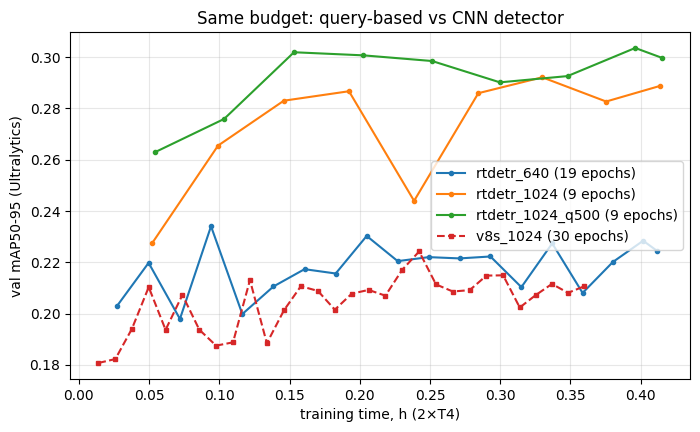

In [7]:
# --- Validation mAP vs training time: RT-DETR runs vs YOLOv8s @1024 --------------------------
plt.figure(figsize=(8, 4.5))
for name in list(RUNS) + [YOLO_REF]:
    d = run_dir(name)
    csv = f"{d}/results.csv" if d else U.find_run_file("results", f"{name}_curve.csv")   # 03 saved its curves
    if not csv or not os.path.exists(csv):
        continue
    h = pd.read_csv(csv)
    h.columns = h.columns.str.strip()
    x = h["time"] / 3600 if "time" in h else h["epoch"] / h["epoch"].max() * TIME_H
    plt.plot(x, h["metrics/mAP50-95(B)"], "o-" if name in RUNS else "s--", ms=3, label=f"{name} ({len(h)} epochs)")
plt.xlabel("training time, h (2×T4)"); plt.ylabel("val mAP50-95 (Ultralytics)")
plt.title("Same budget: query-based vs CNN detector"); plt.grid(alpha=.3); plt.legend()
plt.savefig(f"{WORK}/results/rtdetr_vs_yolo_curves.png", dpi=120, bbox_inches="tight"); plt.show()

## Dense vs sparse scenes

Holdout frames are split at the median object count; each part is evaluated separately.

In [8]:
# --- mAP on sparse and dense frames for the best RT-DETR run and YOLO -------------------------
if results:
    n_obj = va.key.map(anns[anns.iscrowd == 0].groupby("key").size()).fillna(0)
    thr = int(n_obj.median())
    best_rt = max([n for n in results if n in RUNS], key=lambda n: results[n]["mAP"], default=None)
    rows = {}
    for part, mask in [(f"sparse (<= {thr} objects)", n_obj <= thr), (f"dense (> {thr} objects)", n_obj > thr)]:
        sub = va[mask.values]
        gt_sub, k2i = U.make_coco_gt(sub, anns, f"{WORK}/gt_{'dense' if '>' in part else 'sparse'}.json")
        for name in [best_rt, YOLO_REF]:
            if name in dets_by_run:
                coco = [d for k in sub.key for d in U.to_coco_dets(k2i[k], *dets_by_run[name][k])]
                m = U.coco_evaluate(gt_sub, coco)
                rows[(part, name)] = {k: m[k] for k in ["mAP", "AP50", "AP_small", "AR500"]}
    display(pd.DataFrame(rows).T)

,,mAP,AP50,AP_small,AR500
sparse (<= 34 objects),rtdetr_1024_q500,0.291,0.5377,0.1588,0.4907
dense (> 34 objects),rtdetr_1024_q500,0.319,0.5792,0.1548,0.4877


## Bipartite matching instead of NMS

**Matching.** During training the N query predictions are matched one-to-one to the M ground-truth boxes with the Hungarian algorithm, minimising a cost
$C = \lambda_{cls} C_{cls} + \lambda_{L1} \lVert b - \hat b \rVert_1 + \lambda_{giou} (1 - \text{GIoU})$ (Ultralytics: 2 / 5 / 2).
Each object gets exactly one positive query; the remaining N − M queries are trained to predict "no object".
Because a second query on the same object is explicitly penalised as background, the model learns to suppress duplicates itself and **no NMS is needed** at inference: the output is the set of query predictions above a score threshold.

**Training dynamics.** One positive per object (instead of ~10 candidate points per object in YOLOv8's task-aligned assigner) gives a much sparser, less stable training signal, and the matching itself changes between iterations while predictions are poor.
DETR-style models therefore converge slowly; RT-DETR mitigates it with query selection from encoder features, auxiliary losses on every decoder layer and the **denoising** branch (noised GT boxes that must be reconstructed, giving a fixed, matching-free training target).

**Small objects and dense scenes.** RT-DETR's finest feature map has stride 8 and its encoder attention runs on stride 32, so 10–20 px objects are represented by very few features; the number of queries caps the number of detections per image (300 by default, 500 in the tuned run).

## Test submission (best RT-DETR run)

In [9]:
# --- Predict the test set with the best RT-DETR run ---------------------------------------------
def make_submission(name):
    gc.collect(); torch.cuda.empty_cache()
    model, imgsz = load_model(name), imgsz_of(name)
    test = pd.read_csv(os.path.join(U.comp_root(), "test_images.csv"))
    pred = {}
    for i, (image_id, rel) in enumerate(zip(test.image_id, test.file_name)):
        pred[image_id] = U.prediction_string(*boxes_of(predict(model, os.path.join(U.comp_root(), rel), imgsz)[0]))
        if i % 1000 == 0:
            print(f"{i}/{len(test)}")
    sub_path = f"{WORK}/submission_{name}.csv"
    sub = U.write_submission(pred, sub_path)
    with zipfile.ZipFile(sub_path[:-4] + ".zip", "w", zipfile.ZIP_DEFLATED) as z:
        z.write(sub_path, os.path.basename(sub_path))
    print(f"{name}: {len(sub)} rows, csv {os.path.getsize(sub_path) / 1e6:.0f} MB")

if results and best_rt:
    try:
        make_submission(best_rt)
    except Exception:
        traceback.print_exc()

0/3811
1000/3811
2000/3811
3000/3811
rtdetr_1024_q500: 3811 rows, csv 59 MB


## Conclusions

| run | change | mAP | AP50 | AP_small | AP_medium | AP_large | AR500 | FPS | epochs in 0.41 h | public LB |
|---|---|---|---|---|---|---|---|---|---|---|
| `rtdetr_640` | defaults | 0.242 | 0.456 | 0.097 | 0.215 | 0.418 | 0.400 | 13 | 19 | – |
| `rtdetr_1024` | input 1024 | 0.302 | 0.551 | **0.154** | 0.279 | 0.518 | 0.464 | 7 | 9 | – |
| `rtdetr_1024_q500` | + 500 queries | **0.317** | **0.572** | 0.148 | **0.281** | **0.522** | **0.494** | 7 | 9 | **0.3414** |
| `v8s_1024` (nb 03) | CNN reference, same budget | 0.224 | 0.421 | 0.092 | 0.201 | 0.410 | 0.341 | 34 | 30 | 0.2271 |

- **Search range and selection:** input ∈ {640, 1024}, queries ∈ {300, 500}; selected `rtdetr_1024_q500` (best holdout mAP).
- **Input size** is again the largest lever: +0.060 mAP and +59 % `AP_small` (0.097 → 0.154). RT-DETR's finest feature level has stride 8, so at 640 most objects cover only one or two feature cells.
- **More queries help recall in dense frames.** 300 → 500 queries add +0.030 recall and +0.015 mAP, as expected from the EDA (up to 180 objects per frame): with only 300 queries the top-K query selection has little room to propose more than one candidate per object in the densest frames. `AP_small` changes by −0.006, which is within noise.
- **Convergence within the budget.** Unlike classic DETR, RT-DETR does not suffer from slow convergence here: `rtdetr_1024_q500` reaches its plateau (~0.30 Ultralytics mAP) after ~0.15 h (3 epochs) and only fluctuates afterwards (±0.01; `rtdetr_1024` dips by 0.04 at one epoch). Query selection from encoder features, denoising and the COCO-pretrained decoder give it a strong start (0.26 after the first epoch vs 0.18 for YOLO). YOLOv8s is flat at ~0.21 from 0.15 h on, so both models are converged and the gap is not a budget artefact. Part of the gap is capacity: RT-DETR-L has ~3× the parameters of YOLOv8s and is 5× slower at batch 1 (7 vs 34 FPS, FP32 without TensorRT).
- **Small objects and dense scenes.** RT-DETR beats YOLO on every size bucket, most on small objects (0.148 vs 0.092). One-to-one matching without NMS does not hurt dense scenes: frames with more than 34 objects score *higher* (0.319) than sparse ones (0.291), and recall is the same (0.49), so with 500 queries for at most 180 objects the query budget is not the limit. NMS-based detectors, in contrast, have to trade duplicate removal against suppressing true neighbours in tight rows of cars (notebook 01, failure case 1).
- **Leaderboard.** Holdout 0.317 → public LB 0.341, a positive gap like YOLO's (both use Ultralytics' scale augmentation), and the best score of all detectors. RT-DETR therefore becomes the base of the final pipeline (notebook 05).